<a href="https://colab.research.google.com/github/Tulip0648/seismic-fault-impact/blob/main/module3/03_supervised_predictive_modelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 3: Supervised Learning & Baseline Benchmarking

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tulip0648/seismic-fault-impact/blob/main/module3/03_supervised_predictive_modelling.ipynb)

**Course**: BITSF464 Machine Learning — Fall 2026  
**Project**: Seismological Fault Line Discovery & Earthquake Impact Profiling  

---

### Objectives
1. **Two-Stage Benchmarking**: Train and evaluate baseline machine learning algorithms on:
   - **Stage 1 (Base)**: Imputed & standardized physical coordinates and sensor metrics from Module 1.
   - **Stage 2 (Augmented)**: Base features coupled with tectonic fault distances and GMM posterior probabilities from Module 2.
2. **Team Roles**:
   - **Person 1**: Linear & Regularized Models (Logistic Regression with L1/L2/ElasticNet, Ridge/Lasso for MMI).
   - **Person 2**: Probabilistic & Discriminant Models (Gaussian Naive Bayes, LDA with shrinkage, QDA).
   - **Person 3 (Aaryan)**: Distance-Based & Margin Models ($k$-Nearest Neighbors, Support Vector Classifiers with probability calibration).
3. **Module 4 Handoff**: Generate cross-validated Out-of-Fold (OOF) prediction probabilities for the stacking meta-learner.


## 0. Environment Setup (Colab & Local)
Detects environment automatically. Sets data and artifact directories without requiring manual path changes.


In [7]:
import os
import sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Running in Google Colab.")
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_NAME = "seismic-fault-impact"
    REPO_PATH = f"/content/{REPO_NAME}"
    if not os.path.exists(REPO_PATH):
        !git clone https://github.com/Tulip0648/seismic-fault-impact.git {REPO_PATH}
    %cd {REPO_PATH}/module3
    !pip install -r ../requirements.txt -q
    DATA_BASE_DIR = "../data/processed"
    DATA_AUG_DIR = "../data/augmented"
    ARTIFACTS_DIR = "./artifacts"
    REPORTS_DIR = "./reports"
else:
    print("Running locally.")
    DATA_BASE_DIR = "../data/processed"
    DATA_AUG_DIR = "../data/augmented"
    ARTIFACTS_DIR = "./artifacts"
    REPORTS_DIR = "./reports"

os.makedirs(f"{ARTIFACTS_DIR}/models", exist_ok=True)
os.makedirs(f"{ARTIFACTS_DIR}/oof_predictions", exist_ok=True)
os.makedirs(f"{REPORTS_DIR}/figures", exist_ok=True)
print("Directories initialized successfully.")


Running in Google Colab.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/seismic-fault-impact/module3
Directories initialized successfully.


## 1. Imports & Global Configuration


In [8]:
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
N_SPLITS = 5

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Global configuration loaded.")


Global configuration loaded.


## 2. Shared Data Ingestion & Target Preparation
Loads the exact same Base and Augmented datasets created by Module 1 and Module 2.  
Target mapping: `green`: 0, `yellow`: 1, `orange`: 2, `red`: 3.


In [9]:
# Target encoding mapping
ALERT_MAP = {'green': 0, 'yellow': 1, 'orange': 2, 'red': 3}
INV_ALERT_MAP = {v: k for k, v in ALERT_MAP.items()}

# 1. Load Base Splits (Module 1)
train_base = pd.read_parquet(os.path.join(DATA_BASE_DIR, "train_base.parquet"))
val_base = pd.read_parquet(os.path.join(DATA_BASE_DIR, "val_base.parquet"))
test_base = pd.read_parquet(os.path.join(DATA_BASE_DIR, "test_base.parquet"))

# 2. Load Augmented Splits (Module 2)
train_aug = pd.read_parquet(os.path.join(DATA_AUG_DIR, "train_augmented.parquet"))
val_aug = pd.read_parquet(os.path.join(DATA_AUG_DIR, "val_augmented.parquet"))
test_aug = pd.read_parquet(os.path.join(DATA_AUG_DIR, "test_augmented.parquet"))

# 3. Ensure target labels are encoded
for df in [train_base, val_base, test_base, train_aug, val_aug, test_aug]:
    if 'alert_label' not in df.columns and 'alert' in df.columns:
        df['alert_label'] = df['alert'].map(ALERT_MAP)

print(f"Train Base shape:      {train_base.shape}")
print(f"Train Augmented shape: {train_aug.shape}")
print(f"Test Base shape:       {test_base.shape}")
print(f"Test Augmented shape:  {test_aug.shape}")


Train Base shape:      (3105, 46)
Train Augmented shape: (3105, 71)
Test Base shape:       (666, 46)
Test Augmented shape:  (666, 71)


## 3. Feature Selection & Cross-Validation Setup
Defines the feature column subsets and initializes the shared 5-Fold Stratified Cross-Validation splitter.


In [10]:
# Excluded columns (metadata, raw categorical strings, and raw targets)
EXCLUDE_COLS = {'event_id', 'time', 'alert', 'alert_label', 'mmi', 'place', 'magType'}

# Base features: columns present in train_base minus excluded
BASE_FEATURES = [c for c in train_base.columns if c not in EXCLUDE_COLS]

# Augmented features: columns present in train_aug minus excluded
AUGMENTED_FEATURES = [c for c in train_aug.columns if c not in EXCLUDE_COLS]

print(f"Base feature count:       {len(BASE_FEATURES)}")
print(f"Augmented feature count:  {len(AUGMENTED_FEATURES)}")

# Shared Stratified K-Fold splitter
cv_splitter = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

def evaluate_predictions(y_true, y_pred, y_prob=None):
    """Calculates Macro F1, Weighted F1, and Multi-Class ROC-AUC (One-vs-Rest)."""
    metrics = {
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'weighted_f1': f1_score(y_true, y_pred, average='weighted'),
    }
    if y_prob is not None:
        try:
            metrics['roc_auc_ovr'] = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
        except Exception:
            metrics['roc_auc_ovr'] = np.nan
    return metrics


Base feature count:       39
Augmented feature count:  64


---
## 4. Person 1: Linear & Regularized Models
**Owner**: Person 1  
**Models**: Logistic Regression (L1, L2, ElasticNet) & Ridge/Lasso for MMI.  
*(Left empty for Person 1 to implement)*


In [11]:
# --- Person 1: Implement Logistic Regression & Regularized Linear Models here ---


---
## 5. Person 2 (Parshav): Probabilistic & Discriminant Models
**Owner**: Person 2 (Parshav)

**Algorithms**:
1. Gaussian Naive Bayes
2. Linear Discriminant Analysis (LDA)
3. Quadratic Discriminant Analysis (QDA).  

___
### 5.1 Gaussian Naive Bayes — Stage 1 (Base Features)
Implement and tune Gaussian Naive Bayes (`GaussianNB`) on `BASE_FEATURES` using the shared 5-fold stratified cross-validation split:
- Sweep `var_smoothing` $\in [10^{-11}, 10^{-9}, 10^{-7}, 10^{-5}, 10^{-3}, 10^{-2}, 10^{-1}]$ to stabilize variance estimates and prevent zero-variance division errors on rare alert classes (`orange`, `red`).
- Log Macro F1, Weighted F1, and Multi-class ROC-AUC (OvR).

In [12]:
# --- Person 2: Implement Naive Bayes, LDA, and QDA here ---


In [20]:
# Person 2 (Model 1): Gaussian Naive Bayes on Base Features
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define X and y locally so Section 5 can run independently after Cells 0-3
X_base = train_base[BASE_FEATURES]
y_base = train_base['alert_label'].values

var_smoothing_values = [1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1]
gnb_base_results = []

for vs in var_smoothing_values:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []

    for train_idx, val_idx in cv_splitter.split(X_base, y_base):
        X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
        X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('gnb', GaussianNB(var_smoothing=vs))
        ])
        pipeline.fit(X_tr, y_tr)

        y_pred = pipeline.predict(X_va)
        y_prob = pipeline.predict_proba(X_va)

        scores = evaluate_predictions(y_va, y_pred, y_prob)
        fold_macro_f1s.append(scores['macro_f1'])
        fold_weighted_f1s.append(scores['weighted_f1'])
        fold_rocs.append(scores['roc_auc_ovr'])

    gnb_base_results.append({
        'var_smoothing': vs,
        'mean_macro_f1': np.mean(fold_macro_f1s),
        'mean_weighted_f1': np.mean(fold_weighted_f1s),
        'mean_roc_auc': np.mean(fold_rocs)
    })

df_gnb_base = pd.DataFrame(gnb_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_gnb_base_params = df_gnb_base.iloc[0].to_dict()

print("GaussianNB Results on Base Features:")
print(df_gnb_base.round(4).to_string(index=False))
print("\nBest Base GaussianNB Config:", best_gnb_base_params)

GaussianNB Results on Base Features:
 var_smoothing  mean_macro_f1  mean_weighted_f1  mean_roc_auc
         0.010         0.3603            0.8922        0.7502
         0.001         0.3508            0.8903        0.7333
         0.100         0.3444            0.8892        0.7821
         0.000         0.3214            0.8847        0.7065
         0.000         0.3121            0.8833        0.6857
         0.000         0.3112            0.8827        0.6710
         0.000         0.3072            0.8822        0.6587

Best Base GaussianNB Config: {'var_smoothing': 0.01, 'mean_macro_f1': 0.36026953791041233, 'mean_weighted_f1': 0.8922250666212264, 'mean_roc_auc': 0.7501620558781056}


### 5.2 Gaussian Naive Bayes — Stage 2 (Augmented Features)
Train and tune `GaussianNB` on `AUGMENTED_FEATURES` (Base + PCA + DBSCAN + GMM fault features) using the identical 5-fold CV splits, and check the performance delta ($\Delta$) vs. Stage 1.

In [23]:
# Person 2 (Model 1): Gaussian Naive Bayes on Augmented Features
X_aug = train_aug[AUGMENTED_FEATURES]
y_aug = train_aug['alert_label'].values

gnb_aug_results = []

for vs in var_smoothing_values:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []

    for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
        X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
        X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('gnb', GaussianNB(var_smoothing=vs))
        ])
        pipeline.fit(X_tr, y_tr)

        y_pred = pipeline.predict(X_va)
        y_prob = pipeline.predict_proba(X_va)

        scores = evaluate_predictions(y_va, y_pred, y_prob)
        fold_macro_f1s.append(scores['macro_f1'])
        fold_weighted_f1s.append(scores['weighted_f1'])
        fold_rocs.append(scores['roc_auc_ovr'])

    gnb_aug_results.append({
        'var_smoothing': vs,
        'mean_macro_f1': np.mean(fold_macro_f1s),
        'mean_weighted_f1': np.mean(fold_weighted_f1s),
        'mean_roc_auc': np.mean(fold_rocs)
    })

df_gnb_aug = pd.DataFrame(gnb_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_gnb_aug_params = df_gnb_aug.iloc[0].to_dict()

print("GaussianNB Results on Augmented Features:")
print(df_gnb_aug.round(4).to_string(index=False))
print("\nBest Augmented GaussianNB Config:", best_gnb_aug_params)

# Quick delta check for GaussianNB
delta_f1 = best_gnb_aug_params['mean_macro_f1'] - best_gnb_base_params['mean_macro_f1']
delta_auc = best_gnb_aug_params['mean_roc_auc'] - best_gnb_base_params['mean_roc_auc']
print(f"\nGaussianNB Delta -> Δ Macro F1: {delta_f1:+.4f} | Δ ROC-AUC: {delta_auc:+.4f}")

GaussianNB Results on Augmented Features:
 var_smoothing  mean_macro_f1  mean_weighted_f1  mean_roc_auc
         0.100         0.3117            0.8261        0.7305
         0.010         0.2914            0.7727        0.7291
         0.001         0.2833            0.7509        0.7324
         0.000         0.2804            0.7122        0.7300
         0.000         0.2793            0.7243        0.7400
         0.000         0.2773            0.7107        0.7350
         0.000         0.2751            0.7119        0.7385

Best Augmented GaussianNB Config: {'var_smoothing': 0.1, 'mean_macro_f1': 0.31168553784378705, 'mean_weighted_f1': 0.8261346823860082, 'mean_roc_auc': 0.7304820650469812}

GaussianNB Delta -> Δ Macro F1: -0.0486 | Δ ROC-AUC: -0.0197


### 5.3 Linear Discriminant Analysis (LDA) — Stage 1 (Base Features)
Implement and tune `LinearDiscriminantAnalysis` on `BASE_FEATURES` using the shared 5-fold CV split:
- Test solvers: `svd` and `eigen` (plus `lsqr` if needed).
- Test covariance shrinkage (`shrinkage='auto'`, `0.1`, `0.5`) on supported solvers (`eigen`) to stabilize covariance estimation across rare alert classes.

In [24]:
# Person 2 (Model 2): Linear Discriminant Analysis (LDA) on Base Features
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_param_candidates = [
    {'solver': 'svd', 'shrinkage': None},
    {'solver': 'eigen', 'shrinkage': None},
    {'solver': 'eigen', 'shrinkage': 'auto'},
    {'solver': 'eigen', 'shrinkage': 0.1},
    {'solver': 'eigen', 'shrinkage': 0.5},
]

lda_base_results = []

for params in lda_param_candidates:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []
    failed = False

    for train_idx, val_idx in cv_splitter.split(X_base, y_base):
        X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
        X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

        try:
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('lda', LinearDiscriminantAnalysis(
                    solver=params['solver'],
                    shrinkage=params['shrinkage']
                ))
            ])
            pipeline.fit(X_tr, y_tr)

            y_pred = pipeline.predict(X_va)
            y_prob = pipeline.predict_proba(X_va)

            scores = evaluate_predictions(y_va, y_pred, y_prob)
            fold_macro_f1s.append(scores['macro_f1'])
            fold_weighted_f1s.append(scores['weighted_f1'])
            fold_rocs.append(scores['roc_auc_ovr'])
        except Exception as e:
            print(f"Skipping {params} on Base due to numerical error: {e}")
            failed = True
            break

    if not failed:
        lda_base_results.append({
            'solver': params['solver'],
            'shrinkage': str(params['shrinkage']),
            'raw_shrinkage': params['shrinkage'],
            'mean_macro_f1': np.mean(fold_macro_f1s),
            'mean_weighted_f1': np.mean(fold_weighted_f1s),
            'mean_roc_auc': np.mean(fold_rocs)
        })

df_lda_base = pd.DataFrame(lda_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_lda_base_params = df_lda_base.iloc[0].to_dict()

print("LDA Results on Base Features:")
print(df_lda_base.drop(columns=['raw_shrinkage']).round(4).to_string(index=False))
print("\nBest Base LDA Config:", {k: v for k, v in best_lda_base_params.items() if k != 'raw_shrinkage'})

Skipping {'solver': 'eigen', 'shrinkage': None} on Base due to numerical error: The leading minor of order 26 of B is not positive definite. The factorization of B could not be completed and no eigenvalues or eigenvectors were computed.
LDA Results on Base Features:
solver shrinkage  mean_macro_f1  mean_weighted_f1  mean_roc_auc
 eigen       0.5         0.4838            0.9473        0.9335
 eigen       0.1         0.4835            0.9466        0.9538
   svd      None         0.4795            0.9461        0.9443
 eigen      auto         0.4709            0.9449        0.9543

Best Base LDA Config: {'solver': 'eigen', 'shrinkage': '0.5', 'mean_macro_f1': 0.48381210458583634, 'mean_weighted_f1': 0.9473406227278952, 'mean_roc_auc': 0.9335238003589013}


### 5.4 Linear Discriminant Analysis (LDA) — Stage 2 (Augmented Features)
Train and tune `LinearDiscriminantAnalysis` on `AUGMENTED_FEATURES` using the identical 5-fold CV splits, testing whether covariance shrinkage stabilizes the added DBSCAN and GMM fault-line features.

In [25]:
# Person 2 (Model 2): Linear Discriminant Analysis (LDA) on Augmented Features
lda_aug_results = []

for params in lda_param_candidates:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []
    failed = False

    for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
        X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
        X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]

        try:
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('lda', LinearDiscriminantAnalysis(
                    solver=params['solver'],
                    shrinkage=params['shrinkage']
                ))
            ])
            pipeline.fit(X_tr, y_tr)

            y_pred = pipeline.predict(X_va)
            y_prob = pipeline.predict_proba(X_va)

            scores = evaluate_predictions(y_va, y_pred, y_prob)
            fold_macro_f1s.append(scores['macro_f1'])
            fold_weighted_f1s.append(scores['weighted_f1'])
            fold_rocs.append(scores['roc_auc_ovr'])
        except Exception as e:
            print(f"Skipping {params} on Augmented due to numerical error: {e}")
            failed = True
            break

    if not failed:
        lda_aug_results.append({
            'solver': params['solver'],
            'shrinkage': str(params['shrinkage']),
            'raw_shrinkage': params['shrinkage'],
            'mean_macro_f1': np.mean(fold_macro_f1s),
            'mean_weighted_f1': np.mean(fold_weighted_f1s),
            'mean_roc_auc': np.mean(fold_rocs)
        })

df_lda_aug = pd.DataFrame(lda_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_lda_aug_params = df_lda_aug.iloc[0].to_dict()

print("LDA Results on Augmented Features:")
print(df_lda_aug.drop(columns=['raw_shrinkage']).round(4).to_string(index=False))
print("\nBest Augmented LDA Config:", {k: v for k, v in best_lda_aug_params.items() if k != 'raw_shrinkage'})

Skipping {'solver': 'eigen', 'shrinkage': None} on Augmented due to numerical error: The leading minor of order 26 of B is not positive definite. The factorization of B could not be completed and no eigenvalues or eigenvectors were computed.
LDA Results on Augmented Features:
solver shrinkage  mean_macro_f1  mean_weighted_f1  mean_roc_auc
 eigen      auto         0.4589            0.9457        0.9423
   svd      None         0.4589            0.9463        0.9377
 eigen       0.1         0.4549            0.9458        0.9465
 eigen       0.5         0.4443            0.9447        0.9274

Best Augmented LDA Config: {'solver': 'eigen', 'shrinkage': 'auto', 'mean_macro_f1': 0.45890250726035103, 'mean_weighted_f1': 0.9456554464055209, 'mean_roc_auc': 0.9422846824732799}


### 5.5 Quadratic Discriminant Analysis (QDA) — Stage 1 (Base Features)
Implement and tune `QuadraticDiscriminantAnalysis` on `BASE_FEATURES` using the shared 5-fold CV split:
- Sweep `reg_param` $\in [0.0, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9]$ so per-class covariance matrices do not become singular on rare alert classes (`orange`, `red`).
- Log Macro F1, Weighted F1, and Multi-class ROC-AUC (OvR).

In [26]:
# Person 2 (Model 3): Quadratic Discriminant Analysis (QDA) on Base Features
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

reg_param_values = [0.0, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
qda_base_results = []

for rp in reg_param_values:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []
    failed = False

    for train_idx, val_idx in cv_splitter.split(X_base, y_base):
        X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
        X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

        try:
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('qda', QuadraticDiscriminantAnalysis(reg_param=rp))
            ])
            pipeline.fit(X_tr, y_tr)

            y_pred = pipeline.predict(X_va)
            y_prob = pipeline.predict_proba(X_va)

            scores = evaluate_predictions(y_va, y_pred, y_prob)
            fold_macro_f1s.append(scores['macro_f1'])
            fold_weighted_f1s.append(scores['weighted_f1'])
            fold_rocs.append(scores['roc_auc_ovr'])
        except Exception as e:
            print(f"Skipping reg_param={rp} on Base due to error: {e}")
            failed = True
            break

    if not failed:
        qda_base_results.append({
            'reg_param': rp,
            'mean_macro_f1': np.mean(fold_macro_f1s),
            'mean_weighted_f1': np.mean(fold_weighted_f1s),
            'mean_roc_auc': np.mean(fold_rocs)
        })

df_qda_base = pd.DataFrame(qda_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_qda_base_params = df_qda_base.iloc[0].to_dict()

print("QDA Results on Base Features:")
print(df_qda_base.round(4).to_string(index=False))
print("\nBest Base QDA Config:", best_qda_base_params)

QDA Results on Base Features:
 reg_param  mean_macro_f1  mean_weighted_f1  mean_roc_auc
      0.10         0.4452            0.9248        0.8553
      0.30         0.4441            0.9226        0.8664
      0.50         0.4428            0.9190        0.8676
      0.70         0.4388            0.9151        0.8662
      0.05         0.4310            0.9246        0.8516
      0.90         0.4259            0.9089        0.8571
      0.01         0.4178            0.9229        0.8559
      0.00         0.2219            0.6279        0.7512

Best Base QDA Config: {'reg_param': 0.1, 'mean_macro_f1': 0.44521520674853693, 'mean_weighted_f1': 0.9247924206839006, 'mean_roc_auc': 0.8552655616150087}


### 5.6 Quadratic Discriminant Analysis (QDA) — Stage 2 (Augmented Features)
Train and tune `QuadraticDiscriminantAnalysis` on `AUGMENTED_FEATURES` using the identical 5-fold CV splits, evaluating whether curved quadratic boundaries benefit from the added 3D fault-line features.

In [27]:
# Person 2 (Model 3): Quadratic Discriminant Analysis (QDA) on Augmented Features
qda_aug_results = []

for rp in reg_param_values:
    fold_macro_f1s = []
    fold_weighted_f1s = []
    fold_rocs = []
    failed = False

    for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
        X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
        X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]

        try:
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('qda', QuadraticDiscriminantAnalysis(reg_param=rp))
            ])
            pipeline.fit(X_tr, y_tr)

            y_pred = pipeline.predict(X_va)
            y_prob = pipeline.predict_proba(X_va)

            scores = evaluate_predictions(y_va, y_pred, y_prob)
            fold_macro_f1s.append(scores['macro_f1'])
            fold_weighted_f1s.append(scores['weighted_f1'])
            fold_rocs.append(scores['roc_auc_ovr'])
        except Exception as e:
            print(f"Skipping reg_param={rp} on Augmented due to error: {e}")
            failed = True
            break

    if not failed:
        qda_aug_results.append({
            'reg_param': rp,
            'mean_macro_f1': np.mean(fold_macro_f1s),
            'mean_weighted_f1': np.mean(fold_weighted_f1s),
            'mean_roc_auc': np.mean(fold_rocs)
        })

df_qda_aug = pd.DataFrame(qda_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_qda_aug_params = df_qda_aug.iloc[0].to_dict()

print("QDA Results on Augmented Features:")
print(df_qda_aug.round(4).to_string(index=False))
print("\nBest Augmented QDA Config:", best_qda_aug_params)

QDA Results on Augmented Features:
 reg_param  mean_macro_f1  mean_weighted_f1  mean_roc_auc
      0.50         0.4102            0.8784        0.8071
      0.70         0.4048            0.8577        0.7897
      0.30         0.3965            0.8868        0.8190
      0.10         0.3864            0.8809        0.8328
      0.01         0.3853            0.8693        0.8526
      0.90         0.3831            0.7936        0.7697
      0.05         0.3720            0.8696        0.8366
      0.00         0.3217            0.8393        0.7196

Best Augmented QDA Config: {'reg_param': 0.5, 'mean_macro_f1': 0.4102442121304065, 'mean_weighted_f1': 0.8783786044727458, 'mean_roc_auc': 0.80711911500271}


### 5.7 Two-Stage Performance Comparison, LDA vs. QDA & Confusion Matrices
Summarize Base vs. Augmented performance ($\Delta \text{Macro F1}$, $\Delta \text{ROC-AUC}$) across `GaussianNB`, `LDA`, and `QDA`, compare linear (LDA) vs. quadratic (QDA) decision boundaries, and plot confusion matrices.

Person 2 Two-Stage Benchmark Summary:
     Model  Base Macro F1  Augmented Macro F1  Δ Macro F1  Base Weighted F1  Augmented Weighted F1  Base ROC-AUC  Augmented ROC-AUC  Δ ROC-AUC
GaussianNB         0.3603              0.3117     -0.0486            0.8922                 0.8261        0.7502             0.7305    -0.0197
       LDA         0.4838              0.4589     -0.0249            0.9473                 0.9457        0.9335             0.9423     0.0088
       QDA         0.4452              0.4102     -0.0350            0.9248                 0.8784        0.8553             0.8071    -0.0481


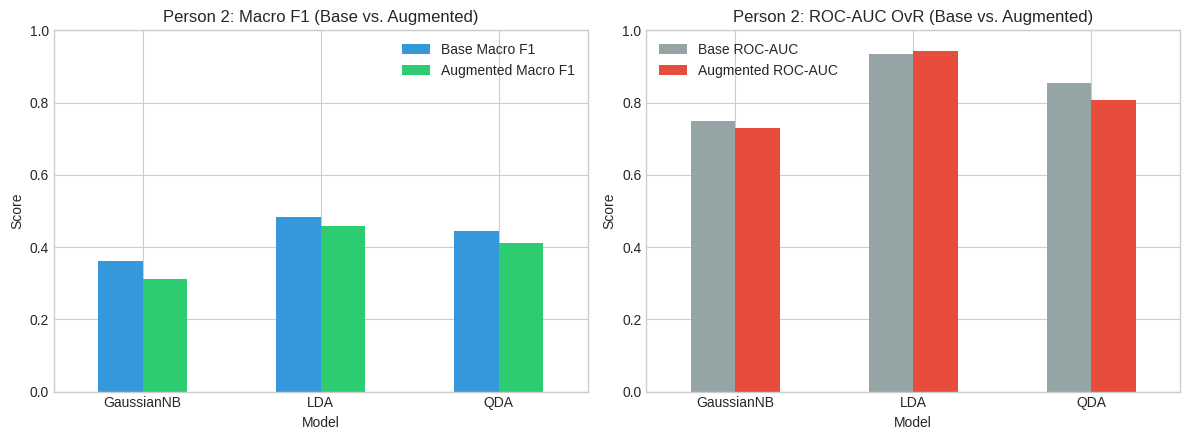

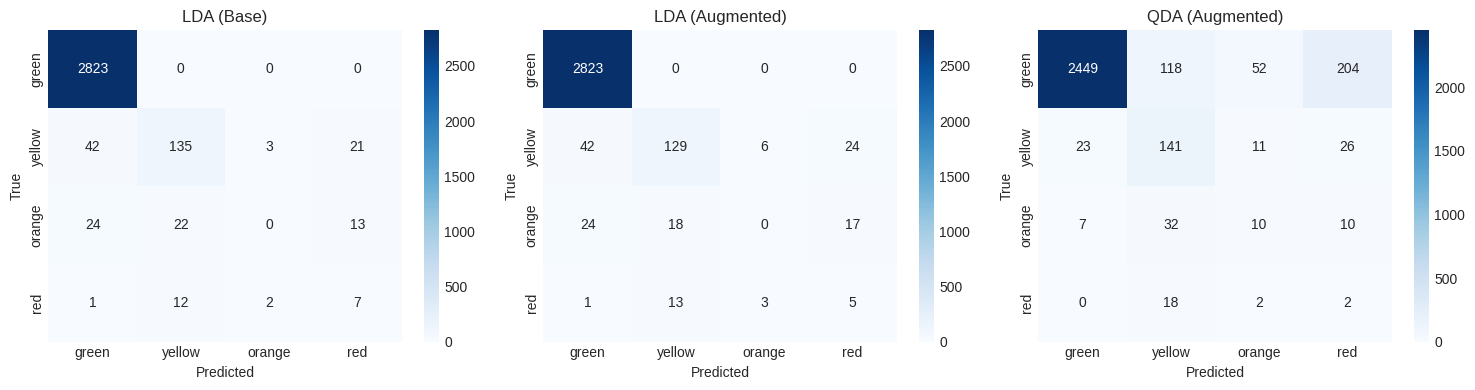


Classification Report — Best Augmented LDA:
              precision    recall  f1-score   support

       green       0.98      1.00      0.99      2823
      yellow       0.81      0.64      0.71       201
      orange       0.00      0.00      0.00        59
         red       0.11      0.23      0.15        22

    accuracy                           0.95      3105
   macro avg       0.47      0.47      0.46      3105
weighted avg       0.94      0.95      0.95      3105



In [28]:
# Person 2: Two-Stage Comparison Table, Plots & Confusion Matrices
p2_comparison_data = [
    {
        'Model': 'GaussianNB',
        'Base Macro F1': best_gnb_base_params['mean_macro_f1'],
        'Augmented Macro F1': best_gnb_aug_params['mean_macro_f1'],
        'Δ Macro F1': best_gnb_aug_params['mean_macro_f1'] - best_gnb_base_params['mean_macro_f1'],
        'Base Weighted F1': best_gnb_base_params['mean_weighted_f1'],
        'Augmented Weighted F1': best_gnb_aug_params['mean_weighted_f1'],
        'Base ROC-AUC': best_gnb_base_params['mean_roc_auc'],
        'Augmented ROC-AUC': best_gnb_aug_params['mean_roc_auc'],
        'Δ ROC-AUC': best_gnb_aug_params['mean_roc_auc'] - best_gnb_base_params['mean_roc_auc'],
    },
    {
        'Model': 'LDA',
        'Base Macro F1': best_lda_base_params['mean_macro_f1'],
        'Augmented Macro F1': best_lda_aug_params['mean_macro_f1'],
        'Δ Macro F1': best_lda_aug_params['mean_macro_f1'] - best_lda_base_params['mean_macro_f1'],
        'Base Weighted F1': best_lda_base_params['mean_weighted_f1'],
        'Augmented Weighted F1': best_lda_aug_params['mean_weighted_f1'],
        'Base ROC-AUC': best_lda_base_params['mean_roc_auc'],
        'Augmented ROC-AUC': best_lda_aug_params['mean_roc_auc'],
        'Δ ROC-AUC': best_lda_aug_params['mean_roc_auc'] - best_lda_base_params['mean_roc_auc'],
    },
    {
        'Model': 'QDA',
        'Base Macro F1': best_qda_base_params['mean_macro_f1'],
        'Augmented Macro F1': best_qda_aug_params['mean_macro_f1'],
        'Δ Macro F1': best_qda_aug_params['mean_macro_f1'] - best_qda_base_params['mean_macro_f1'],
        'Base Weighted F1': best_qda_base_params['mean_weighted_f1'],
        'Augmented Weighted F1': best_qda_aug_params['mean_weighted_f1'],
        'Base ROC-AUC': best_qda_base_params['mean_roc_auc'],
        'Augmented ROC-AUC': best_qda_aug_params['mean_roc_auc'],
        'Δ ROC-AUC': best_qda_aug_params['mean_roc_auc'] - best_qda_base_params['mean_roc_auc'],
    }
]

df_p2_comparison = pd.DataFrame(p2_comparison_data)
print("Person 2 Two-Stage Benchmark Summary:")
print(df_p2_comparison.round(4).to_string(index=False))

# Plot Macro F1 & ROC-AUC comparisons
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df_p2_comparison.plot(x='Model', y=['Base Macro F1', 'Augmented Macro F1'], kind='bar', ax=axes[0], color=['#3498db', '#2ecc71'])
axes[0].set_title('Person 2: Macro F1 (Base vs. Augmented)')
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel('Score')
axes[0].tick_params(axis='x', rotation=0)

df_p2_comparison.plot(x='Model', y=['Base ROC-AUC', 'Augmented ROC-AUC'], kind='bar', ax=axes[1], color=['#95a5a6', '#e74c3c'])
axes[1].set_title('Person 2: ROC-AUC OvR (Base vs. Augmented)')
axes[1].set_ylim(0, 1.0)
axes[1].set_ylabel('Score')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(f"{REPORTS_DIR}/figures/person2_base_vs_augmented.png", dpi=150)
plt.show()

# Generate 5-fold OOF confusion matrices for best LDA (Base vs Augmented) & QDA (Augmented)
def get_oof_preds(pipe_fn, X_df, y_arr):
    oof_pred = np.zeros(len(y_arr), dtype=int)
    for tr_idx, va_idx in cv_splitter.split(X_df, y_arr):
        p = pipe_fn()
        p.fit(X_df.iloc[tr_idx], y_arr[tr_idx])
        oof_pred[va_idx] = p.predict(X_df.iloc[va_idx])
    return oof_pred

lda_base_shrink = None if pd.isna(best_lda_base_params['raw_shrinkage']) else best_lda_base_params['raw_shrinkage']
lda_aug_shrink = None if pd.isna(best_lda_aug_params['raw_shrinkage']) else best_lda_aug_params['raw_shrinkage']

oof_pred_lda_base = get_oof_preds(
    lambda: Pipeline([('scaler', StandardScaler()), ('lda', LinearDiscriminantAnalysis(solver=best_lda_base_params['solver'], shrinkage=lda_base_shrink))]),
    X_base, y_base
)
oof_pred_lda_aug = get_oof_preds(
    lambda: Pipeline([('scaler', StandardScaler()), ('lda', LinearDiscriminantAnalysis(solver=best_lda_aug_params['solver'], shrinkage=lda_aug_shrink))]),
    X_aug, y_aug
)
oof_pred_qda_aug = get_oof_preds(
    lambda: Pipeline([('scaler', StandardScaler()), ('qda', QuadraticDiscriminantAnalysis(reg_param=best_qda_aug_params['reg_param']))]),
    X_aug, y_aug
)

class_names = [INV_ALERT_MAP[i] for i in range(len(ALERT_MAP))]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, preds, title in zip(
    axes,
    [oof_pred_lda_base, oof_pred_lda_aug, oof_pred_qda_aug],
    ['LDA (Base)', 'LDA (Augmented)', 'QDA (Augmented)']
):
    cm = confusion_matrix(y_aug, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.savefig(f"{REPORTS_DIR}/figures/person2_confusion_matrices.png", dpi=150)
plt.show()

print("\nClassification Report — Best Augmented LDA:")
print(classification_report(y_aug, oof_pred_lda_aug, target_names=class_names))

### 5.8 Out-of-Fold (OOF) Prediction Export & Model Serialization
1. Fit the final tuned LDA and QDA models on the full `AUGMENTED_FEATURES` training set and serialize to `artifacts/models/`:
   - `lda_aug.joblib`
   - `qda_aug.joblib`
2. Generate 5-fold cross-validated Out-of-Fold (OOF) probabilities and test set probabilities from tuned LDA, verify row-wise probability sums equal `1.0`, and export `oof_train_person2.parquet` and `oof_test_person2.parquet`.

In [29]:
# Person 2: Model Serialization & OOF Export for Module 4
best_lda_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(
        solver=best_lda_aug_params['solver'],
        shrinkage=lda_aug_shrink
    ))
])

best_qda_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('qda', QuadraticDiscriminantAnalysis(
        reg_param=float(best_qda_aug_params['reg_param'])
    ))
])

# 1. Generate 5-fold OOF probabilities for LDA on train_aug
n_classes = len(ALERT_MAP)
oof_lda_train = np.zeros((len(train_aug), n_classes))

for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
    X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
    X_va = X_aug.iloc[val_idx]

    best_lda_pipe.fit(X_tr, y_tr)
    oof_lda_train[val_idx] = best_lda_pipe.predict_proba(X_va)

# 2. Fit both LDA & QDA on full training set and predict test probabilities
best_lda_pipe.fit(X_aug, y_aug)
best_qda_pipe.fit(X_aug, y_aug)

X_test_aug = test_aug[AUGMENTED_FEATURES]
test_lda_probs = best_lda_pipe.predict_proba(X_test_aug)

# Sanity check: probabilities sum to 1.0 across rows
assert np.allclose(oof_lda_train.sum(axis=1), 1.0), "OOF LDA probabilities do not sum to 1.0!"
assert np.allclose(test_lda_probs.sum(axis=1), 1.0), "Test LDA probabilities do not sum to 1.0!"

# 3. Serialize models to artifacts/models/
joblib.dump(best_lda_pipe, f"{ARTIFACTS_DIR}/models/lda_aug.joblib")
joblib.dump(best_qda_pipe, f"{ARTIFACTS_DIR}/models/qda_aug.joblib")
print(f"Serialized lda_aug.joblib and qda_aug.joblib to {ARTIFACTS_DIR}/models/")

# 4. Save Person 2 OOF predictions matching Person 3's schema
oof_p2_train_df = pd.DataFrame({'event_id': train_aug['event_id'], 'true_label': y_aug})
oof_p2_test_df = pd.DataFrame({'event_id': test_aug['event_id'], 'true_label': test_aug['alert_label']})

for c_idx, c_name in INV_ALERT_MAP.items():
    oof_p2_train_df[f'lda_prob_{c_name}'] = oof_lda_train[:, c_idx]
    oof_p2_test_df[f'lda_prob_{c_name}'] = test_lda_probs[:, c_idx]

oof_p2_train_df.to_parquet(f"{ARTIFACTS_DIR}/oof_predictions/oof_train_person2.parquet", index=False)
oof_p2_test_df.to_parquet(f"{ARTIFACTS_DIR}/oof_predictions/oof_test_person2.parquet", index=False)

print(f"Person 2 OOF saved: train shape {oof_p2_train_df.shape}, test shape {oof_p2_test_df.shape}")
print(oof_p2_train_df.head())

Serialized lda_aug.joblib and qda_aug.joblib to ./artifacts/models/
Person 2 OOF saved: train shape (3105, 6), test shape (666, 6)
     event_id  true_label  lda_prob_green  lda_prob_yellow  lda_prob_orange  \
0  usc000p27i           1    3.056476e-14     4.771246e-01     3.971783e-04   
1  us60008bj6           0    1.000000e+00     4.119727e-14     5.579779e-11   
2  us6000le2y           0    1.000000e+00     7.040101e-11     2.269442e-08   
3  us6000ldsf           0    1.000000e+00     9.422626e-14     6.493513e-11   
4  us7000clbu           0    1.000000e+00     2.260402e-13     2.170769e-10   

   lda_prob_red  
0  5.224782e-01  
1  5.932602e-21  
2  3.942779e-20  
3  1.499247e-21  
4  2.015197e-19  


---
## 6. Person 3 (Aaryan): Distance-Based & Margin Models

**Owner**: Person 3 (Aaryan)  
**Algorithms**:
1. **k-Nearest Neighbors (k-NN)**: Distance-based classification.
2. **Support Vector Classifier (SVC)**: Maximum margin classification with kernel transformations and probability calibration.

---

### 6.1 k-Nearest Neighbors (k-NN) — Stage 1 (Base Features)
Implement and tune $k$-NN on `BASE_FEATURES` using the 5-fold cross-validation split:
- Sweep $k \in [3, 5, 7, 11, 15, 21]$.
- Compare `weights='uniform'` vs `weights='distance'`.
- Compare distance metric (`metric='euclidean'` vs `metric='manhattan'`).


In [13]:
# DONE (Person 3): Export fitted models (.joblib) and generate OOF prediction vectors
# DONE (Person 3): Implement k-NN on Base Features
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

class CustomKNN(BaseEstimator, ClassifierMixin):
    def __init__(self, k=5, metric='euclidean', weights='uniform'):
        self.k = k
        self.metric = metric
        self.weights = weights

    def fit(self, X, y):
        self.X_train_ = np.asarray(X)
        self.y_train_ = np.asarray(y)
        self.classes_ = np.unique(y)
        return self

    def predict_proba(self, X):
        X = np.asarray(X)
        # performs pairwise distance calculation
        if self.metric == 'euclidean':
            #  The correct formula:
            sq_dists = (
                np.sum(X**2, axis=1, keepdims=True)
                + np.sum(self.X_train_**2, axis=1)
                - 2 * np.dot(X, self.X_train_.T)
            )
            dists = np.sqrt(np.maximum(0.0, sq_dists))
        else:
            dists = np.sum(
                np.abs(X[:, None, :]) - self.X_train_[None, :, :], axis=2
            )
        knn_indices = np.argpartition(dists, self.k, axis=1)[:, :self.k]
        probs = np.zeros((len(X), len(self.classes_)))
        for i, idx in enumerate(knn_indices):
            neighbour_labels = self.y_train_[idx]
            if self.weights == 'distance':
                neighbour_dists = dists[i, idx]
                w = 1/(neighbour_dists+1e-5)
                for label, weight in zip(neighbour_labels, w):
                    probs[i, label] += weight
                total_w = np.sum(w)
                if total_w > 0:
                    probs[i] = probs[i]/total_w
                else:
                    probs[i] = probs[i] = 1.0 / len(self.classes_)
            else:
                counts = np.bincount(neighbour_labels, minlength=len(self.classes_))
                probs[i] = counts/self.k
        return probs

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

X_base = train_base[BASE_FEATURES]
y_base = train_base['alert_label'].values

k_values = [3,5,7,11,15,21]
weights_list = ['uniform', 'distance']
metrics_list = ['euclidean', 'manhattan']

knn_base_results = []

for k in k_values:
    for w in weights_list:
        for m in metrics_list:
            fold_macro_f1s = []
            fold_rocs = []

            for train_idx, val_idx in cv_splitter.split(X_base, y_base):
                X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
                X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

                pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('knn', CustomKNN(k=k, weights=w, metric=m))
                ])
                pipeline.fit(X_tr, y_tr)

                y_pred = pipeline.predict(X_va)
                y_prob = pipeline.predict_proba(X_va)

                scores = evaluate_predictions(y_va, y_pred, y_prob)
                fold_macro_f1s.append(scores['macro_f1'])
                fold_rocs.append(scores['roc_auc_ovr'])

            knn_base_results.append(
                {
                    'k': k,
                    'weights': w,
                    'metric': m,
                    'mean_macro_f1': np.mean(fold_macro_f1s),
                    'mean_roc_auc': np.mean(fold_rocs)
                }
            )

df_knn_base = pd.DataFrame(knn_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_knn_base_params = df_knn_base.iloc[0].to_dict()

print("Top 3 k-NN configs on base features:")
print(df_knn_base.head(3))

Top 3 k-NN configs on base features:
    k   weights     metric  mean_macro_f1  mean_roc_auc
6   5  distance  euclidean       0.492542      0.829643
2   3  distance  euclidean       0.492479      0.806615
10  7  distance  euclidean       0.463326      0.851537


### 6.2 k-Nearest Neighbors (k-NN) — Stage 2 (Augmented Features)
Train and evaluate the best $k$-NN configuration on `AUGMENTED_FEATURES` using the identical 5-fold CV splits.


In [14]:
# DONE (Person 3): Implement k-NN on Augmented Features
X_aug = train_aug[AUGMENTED_FEATURES]
y_aug = train_aug['alert_label'].values

knn_aug_results = []

for k in k_values:
    for w in weights_list:
        for m in metrics_list:
            fold_macro_f1s = []
            fold_rocs = []

            for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
                X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
                X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]

                pipeline = Pipeline([
                    ('scaler', StandardScaler()),
                    ('knn', CustomKNN(k=k, weights=w, metric=m))
                ])
                pipeline.fit(X_tr, y_tr)

                y_pred = pipeline.predict(X_va)
                y_prob = pipeline.predict_proba(X_va)

                scores = evaluate_predictions(y_va, y_pred, y_prob)
                fold_macro_f1s.append(scores['macro_f1'])
                fold_rocs.append(scores['roc_auc_ovr'])

            knn_aug_results.append({
                'k': k,
                'weights': w,
                'metric': m,
                'mean_macro_f1': np.mean(fold_macro_f1s),
                'mean_roc_auc': np.mean(fold_rocs)
            })

df_knn_aug = pd.DataFrame(knn_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_knn_aug_params = df_knn_aug.iloc[0].to_dict()

print("Top 3 Custom k-NN Configurations on Augmented Features:")
print(df_knn_aug.head(3))

Top 3 Custom k-NN Configurations on Augmented Features:
   k   weights     metric  mean_macro_f1  mean_roc_auc
2  3  distance  euclidean       0.475776      0.778665
6  5  distance  euclidean       0.475002      0.819010
0  3   uniform  euclidean       0.474839      0.778098


### 6.3 Support Vector Classifier (SVC) — Stage 1 (Base Features)
Implement and tune SVC on `BASE_FEATURES`:
- Compare kernels: `kernel='linear'`, `kernel='rbf'`, `kernel='poly'`.
- Tune regularization parameter $C \in [0.1, 1.0, 10.0, 100.0]$ and $\gamma$ (`gamma`).
- Use `class_weight='balanced'` to account for minority classes (Orange & Red).
- Ensure probability calibration is enabled (`probability=True` or `CalibratedClassifierCV`).


In [15]:
# DONE (Person 3): Implement SVC on Base Features
from sklearn.svm import SVC

# Kernel and hyperparameter candidates
# Note: probability=True enables Platt scaling so probabilities sum to 1.0
svc_param_candidates = [
    {'kernel': 'linear', 'C': 1.0, 'gamma': 'scale'},
    {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'},
    {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'},
    {'kernel': 'rbf', 'C': 10.0, 'gamma': 'auto'},
    {'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gamma': 'scale'}
]

svc_base_results = []

for params in svc_param_candidates:
    fold_macro_f1s = []
    fold_rocs = []

    for train_idx, val_idx in cv_splitter.split(X_base, y_base):
        X_tr, y_tr = X_base.iloc[train_idx], y_base[train_idx]
        X_va, y_va = X_base.iloc[val_idx], y_base[val_idx]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('svc', SVC(
                kernel=params['kernel'],
                C=params['C'],
                gamma=params['gamma'],
                degree=params.get('degree', 3),
                class_weight='balanced',
                probability=True,
                random_state=RANDOM_STATE
            ))
        ])
        pipeline.fit(X_tr, y_tr)

        y_pred = pipeline.predict(X_va)
        y_prob = pipeline.predict_proba(X_va)

        scores = evaluate_predictions(y_va, y_pred, y_prob)
        fold_macro_f1s.append(scores['macro_f1'])
        fold_rocs.append(scores['roc_auc_ovr'])

    svc_base_results.append({
        'config': str(params),
        'kernel': params['kernel'],
        'C': params['C'],
        'gamma': params['gamma'],
        'mean_macro_f1': np.mean(fold_macro_f1s),
        'mean_roc_auc': np.mean(fold_rocs)
    })

df_svc_base = pd.DataFrame(svc_base_results).sort_values(by='mean_macro_f1', ascending=False)
best_svc_base_params = df_svc_base.iloc[0].to_dict()

print("SVC Configurations on Base Features:")
print(df_svc_base)
print("Best Base SVC Parameters:", best_svc_base_params)

SVC Configurations on Base Features:
                                              config  kernel     C  gamma  \
1      {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}     rbf   1.0  scale   
0   {'kernel': 'linear', 'C': 1.0, 'gamma': 'scale'}  linear   1.0  scale   
2     {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}     rbf  10.0  scale   
3      {'kernel': 'rbf', 'C': 10.0, 'gamma': 'auto'}     rbf  10.0   auto   
4  {'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gam...    poly   1.0  scale   

   mean_macro_f1  mean_roc_auc  
1       0.469203      0.960098  
0       0.468630      0.964086  
2       0.468161      0.958918  
3       0.468161      0.958918  
4       0.438985      0.946416  
Best Base SVC Parameters: {'config': "{'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}", 'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale', 'mean_macro_f1': 0.46920317948501183, 'mean_roc_auc': 0.9600977844055549}


### 6.4 Support Vector Classifier (SVC) — Stage 2 (Augmented Features)
Train and evaluate the best SVC configuration on `AUGMENTED_FEATURES` using the identical 5-fold CV splits.


In [16]:
# DONE (Person 3): Implement SVC on Augmented Features
svc_aug_results = []

for params in svc_param_candidates:
    fold_macro_f1s = []
    fold_rocs = []

    for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
        X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
        X_va, y_va = X_aug.iloc[val_idx], y_aug[val_idx]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('svc', SVC(
                kernel=params['kernel'],
                C=params['C'],
                gamma=params['gamma'],
                degree=params.get('degree', 3),
                class_weight='balanced',
                probability=True,
                random_state=RANDOM_STATE
            ))
        ])
        pipeline.fit(X_tr, y_tr)

        y_pred = pipeline.predict(X_va)
        y_prob = pipeline.predict_proba(X_va)

        scores = evaluate_predictions(y_va, y_pred, y_prob)
        fold_macro_f1s.append(scores['macro_f1'])
        fold_rocs.append(scores['roc_auc_ovr'])

    svc_aug_results.append({
        'config': str(params),
        'kernel': params['kernel'],
        'C': params['C'],
        'gamma': params['gamma'],
        'mean_macro_f1': np.mean(fold_macro_f1s),
        'mean_roc_auc': np.mean(fold_rocs)
    })

df_svc_aug = pd.DataFrame(svc_aug_results).sort_values(by='mean_macro_f1', ascending=False)
best_svc_aug_params = df_svc_aug.iloc[0].to_dict()

print("SVC Configurations on Augmented Features:")
print(df_svc_aug)
print("Best Augmented SVC Parameters:", best_svc_aug_params)

SVC Configurations on Augmented Features:
                                              config  kernel     C  gamma  \
4  {'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gam...    poly   1.0  scale   
3      {'kernel': 'rbf', 'C': 10.0, 'gamma': 'auto'}     rbf  10.0   auto   
2     {'kernel': 'rbf', 'C': 10.0, 'gamma': 'scale'}     rbf  10.0  scale   
1      {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale'}     rbf   1.0  scale   
0   {'kernel': 'linear', 'C': 1.0, 'gamma': 'scale'}  linear   1.0  scale   

   mean_macro_f1  mean_roc_auc  
4       0.488826      0.949674  
3       0.486158      0.961553  
2       0.486158      0.961553  
1       0.468509      0.960578  
0       0.467034      0.962722  
Best Augmented SVC Parameters: {'config': "{'kernel': 'poly', 'degree': 2, 'C': 1.0, 'gamma': 'scale'}", 'kernel': 'poly', 'C': 1.0, 'gamma': 'scale', 'mean_macro_f1': 0.4888260622373218, 'mean_roc_auc': 0.949674141170785}


### 6.5 Two-Stage Performance Comparison for Person 3 Models
Calculate the improvement gained by adding tectonic fault features:
$$\Delta \text{Macro F1} = \text{Macro F1}_{\text{Augmented}} - \text{Macro F1}_{\text{Base}}$$
$$\Delta \text{ROC-AUC} = \text{ROC-AUC}_{\text{Augmented}} - \text{ROC-AUC}_{\text{Base}}$$


  Model  Base Macro F1  Augmented Macro F1  Δ Macro F1  Base ROC-AUC  \
0  k-NN         0.4925              0.4758     -0.0168        0.8296   
1   SVC         0.4692              0.4888      0.0196        0.9601   

   Augmented ROC-AUC  Δ ROC-AUC  
0             0.7787    -0.0510  
1             0.9497    -0.0104  


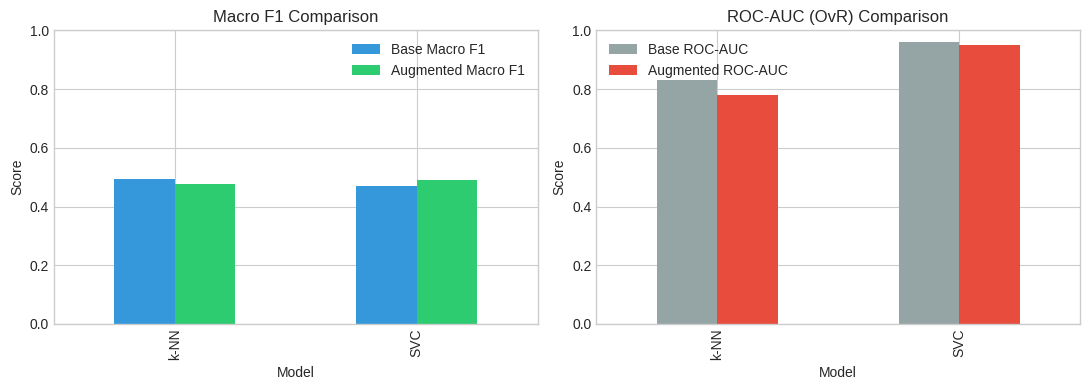

In [17]:
# TODO (Person 3): Compare Base vs Augmented performance (delta table and plot)
# Create comparison dataframe for Person 3's models
comparison_data = [
    {
        'Model': 'k-NN',
        'Base Macro F1': df_knn_base.iloc[0]['mean_macro_f1'],
        'Augmented Macro F1': df_knn_aug.iloc[0]['mean_macro_f1'],
        'Δ Macro F1': df_knn_aug.iloc[0]['mean_macro_f1'] - df_knn_base.iloc[0]['mean_macro_f1'],
        'Base ROC-AUC': df_knn_base.iloc[0]['mean_roc_auc'],
        'Augmented ROC-AUC': df_knn_aug.iloc[0]['mean_roc_auc'],
        'Δ ROC-AUC': df_knn_aug.iloc[0]['mean_roc_auc'] - df_knn_base.iloc[0]['mean_roc_auc'],
    },
    {
        'Model': 'SVC',
        'Base Macro F1': df_svc_base.iloc[0]['mean_macro_f1'],
        'Augmented Macro F1': df_svc_aug.iloc[0]['mean_macro_f1'],
        'Δ Macro F1': df_svc_aug.iloc[0]['mean_macro_f1'] - df_svc_base.iloc[0]['mean_macro_f1'],
        'Base ROC-AUC': df_svc_base.iloc[0]['mean_roc_auc'],
        'Augmented ROC-AUC': df_svc_aug.iloc[0]['mean_roc_auc'],
        'Δ ROC-AUC': df_svc_aug.iloc[0]['mean_roc_auc'] - df_svc_base.iloc[0]['mean_roc_auc'],
    }
]

df_comparison = pd.DataFrame(comparison_data)
#  Simple, clean, and requires zero extra packages:
print(df_comparison.round(4))

# Plot performance delta comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_comparison.plot(x='Model', y=['Base Macro F1', 'Augmented Macro F1'], kind='bar', ax=axes[0], color=['#3498db', '#2ecc71'])
axes[0].set_title('Macro F1 Comparison')
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel('Score')

df_comparison.plot(x='Model', y=['Base ROC-AUC', 'Augmented ROC-AUC'], kind='bar', ax=axes[1], color=['#95a5a6', '#e74c3c'])
axes[1].set_title('ROC-AUC (OvR) Comparison')
axes[1].set_ylim(0, 1.0)
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.savefig(f"{REPORTS_DIR}/figures/person3_base_vs_augmented.png", dpi=150)
plt.show()

### 6.6 Out-of-Fold (OOF) Prediction Export & Model Serialization
1. Fit the final tuned $k$-NN and SVC models on the full training set and serialize to `artifacts/models/`:
   - `knn_aug.joblib`
   - `svm_rbf_aug.joblib`
2. Save out-of-fold cross-validated probability predictions for both $k$-NN and SVC.


In [18]:
#DONE
# 1. Instantiate best pipelines (CustomKNN + SVC)
best_k = int(best_knn_aug_params['k'])
best_w = best_knn_aug_params['weights']
best_m = best_knn_aug_params['metric']

best_knn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', CustomKNN(k=best_k, weights=best_w, metric=best_m))
])

best_svc_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(
        kernel=best_svc_aug_params['kernel'],
        C=best_svc_aug_params['C'],
        gamma=best_svc_aug_params['gamma'],
        class_weight='balanced',
        probability=True,
        random_state=RANDOM_STATE
    ))
])

# 2. Out-of-Fold (OOF) cross-validation predictions on the training set
n_classes = len(ALERT_MAP)
oof_knn_train = np.zeros((len(train_aug), n_classes))
oof_svc_train = np.zeros((len(train_aug), n_classes))

for train_idx, val_idx in cv_splitter.split(X_aug, y_aug):
    X_tr, y_tr = X_aug.iloc[train_idx], y_aug[train_idx]
    X_va = X_aug.iloc[val_idx]

    best_knn_pipe.fit(X_tr, y_tr)
    oof_knn_train[val_idx] = best_knn_pipe.predict_proba(X_va)

    best_svc_pipe.fit(X_tr, y_tr)
    oof_svc_train[val_idx] = best_svc_pipe.predict_proba(X_va)

# 3. Fit on the full training set and predict on the test set
best_knn_pipe.fit(X_aug, y_aug)
best_svc_pipe.fit(X_aug, y_aug)

X_test_aug = test_aug[AUGMENTED_FEATURES]
test_knn_probs = best_knn_pipe.predict_proba(X_test_aug)
test_svc_probs = best_svc_pipe.predict_proba(X_test_aug)

# 4. Serialize models to artifacts/models/
joblib.dump(best_knn_pipe, f"{ARTIFACTS_DIR}/models/knn_aug.joblib")
joblib.dump(best_svc_pipe, f"{ARTIFACTS_DIR}/models/svm_rbf_aug.joblib")
print(f"Serialized models to {ARTIFACTS_DIR}/models/")

# 5. Format OOF prediction columns
oof_p3_train_df = pd.DataFrame({'event_id': train_aug['event_id'], 'true_label': y_aug})
oof_p3_test_df = pd.DataFrame({'event_id': test_aug['event_id'], 'true_label': test_aug['alert_label']})

for c_idx, c_name in INV_ALERT_MAP.items():
    oof_p3_train_df[f'knn_prob_{c_name}'] = oof_knn_train[:, c_idx]
    oof_p3_train_df[f'svm_prob_{c_name}'] = oof_svc_train[:, c_idx]
    oof_p3_test_df[f'knn_prob_{c_name}'] = test_knn_probs[:, c_idx]
    oof_p3_test_df[f'svm_prob_{c_name}'] = test_svc_probs[:, c_idx]

# Save Person 3 OOF artifacts
oof_p3_train_df.to_parquet(f"{ARTIFACTS_DIR}/oof_predictions/oof_train_person3.parquet", index=False)
oof_p3_test_df.to_parquet(f"{ARTIFACTS_DIR}/oof_predictions/oof_test_person3.parquet", index=False)

print(f"Person 3 OOF saved: train shape {oof_p3_train_df.shape}, test shape {oof_p3_test_df.shape}")
print(oof_p3_train_df.head())

Serialized models to ./artifacts/models/
Person 3 OOF saved: train shape (3105, 10), test shape (666, 10)
     event_id  true_label  knn_prob_green  svm_prob_green  knn_prob_yellow  \
0  usc000p27i           1             0.0        0.086593         0.719274   
1  us60008bj6           0             1.0        0.985765         0.000000   
2  us6000le2y           0             1.0        0.996041         0.000000   
3  us6000ldsf           0             1.0        0.989351         0.000000   
4  us7000clbu           0             1.0        0.985253         0.000000   

   svm_prob_yellow  knn_prob_orange  svm_prob_orange  knn_prob_red  \
0         0.739835         0.280726         0.132483           0.0   
1         0.009011         0.000000         0.004108           0.0   
2         0.001308         0.000000         0.002140           0.0   
3         0.006202         0.000000         0.003425           0.0   
4         0.009859         0.000000         0.003530           0.0   

   s

---
## 7. Final Consolidation: Module 4 Stacking Handoff
Combines OOF predictions from Person 1, Person 2, and Person 3 into `oof_train_m3.parquet` and `oof_test_m3.parquet` for Module 4.


In [19]:
# --- Consolidation Cell: Merges OOF columns from all 3 roles once ready ---
